<div align="center">

<img src="Logo_inpt.png" alt="INPT" width="160">


<br>
<h3 align="center">Institut National des Postes et Télécommunications (INPT)</h3>

<br><br>
<h1 align="center">Laaouafi Fatiha</h1>
<a href= "https://github.com/LAAOUAFIFATIHA/Math-for-AI/">Github link for this project</a>

</div>

In [1]:
## Start

# Numerical Integration: Composite Trapezoidal Rule vs Composite Simpson Rule

EX: implement the two algorithms and compare their error as a function of the number of subintervals `n`.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Algorithm 1: Composite Trapezoidal Rule

The **Composite Trapezoidal Rule** is a numerical integration method used to approximate a definite integral. It divides the integration interval $[a,b]$ into $n$ equal subintervals and approximates the area under the curve by a sum of trapezoids. The more subintervals used, the more accurate the approximation generally becomes.

**Formula:**

$$
I \approx \frac{h}{2}
\left[
f(a)+2\sum_{i=1}^{n-1}f(x_i)+f(b)
\right]
$$

where:

- $h = \frac{b-a}{n}$ is the width of each subinterval.
- $x_i = a + ih$ are the division points.
- $n$ is the number of subintervals.
- $f(a)$ and $f(b)$ are the function values at the endpoints.


In [3]:
def trapezoidal(f, a, b, n):
    h = (b - a) / n
    S = f(a) + f(b)
    for i in range(1, n):
        x = a + i * h
        S += 2 * f(x)
    return h / 2 * S

## 2. Algorithm 2: Composite Simpson Rule (n must be even)


The **Composite Simpson Rule** is a numerical integration method used to approximate a definite integral. It divides the integration interval $[a,b]$ into $n$ equal subintervals, where $n$ must be even. Instead of approximating the curve with straight lines, it uses parabolas to estimate the area under the curve. It is generally more accurate than the Composite Trapezoidal Rule for sufficiently smooth functions.

**Formula:**

$$
I \approx \frac{h}{3}
\left[
f(a)
+4\sum_{\substack{i=1\\i\text{ odd}}}^{n-1} f(x_i)
+2\sum_{\substack{i=2\\i\text{ even}}}^{n-2} f(x_i)
+f(b)
\right]
$$

where:

- $h = \frac{b-a}{n}$ is the width of each subinterval.
- $x_i = a + ih$ are the division points.
- $n$ is the number of subintervals and must be even.
- The coefficient $4$ is used for odd-indexed interior points.
- The coefficient $2$ is used for even-indexed interior points, excluding the endpoints.
- $f(a)$ and $f(b)$ are the function values at the endpoints.


In [8]:
def simpson(f, a, b, n):
    if n % 2 != 0:
        raise ValueError('n must be even')
    h = (b - a) / n
    I = f(a)
    for i in range(1, n):
        x = a + i * h
        if i % 2 == 1:
            I += 4 * f(x)
        else:
            I += 2 * f(x)
    I += f(b)
    return I * h / 3

## 3. Error comparison function

We pick a function whose exact integral is known, then compute the absolute error for several values of `n`.

In [9]:
def compare(f, a, b, exact, name, ns=(2, 4, 8, 16, 32, 64, 128, 256, 512, 1024)):
    err_trap, err_simp = [], []
    for n in ns:
        It = trapezoidal(f, a, b, n)
        Is = simpson(f, a, b, n)
        et, es = abs(It - exact), abs(Is - exact)
        err_trap.append(et)
        err_simp.append(es)

    
    plt.figure(figsize=(7, 5))
    plt.loglog(ns, err_trap, 'o-', label='Trapezoidal', color='green')
    plt.loglog(ns, err_simp, 's-', label='Simpson', color='blue')
    plt.xlabel('n (number of subintervals)')
    plt.ylabel('Absolute error')
    plt.title(f'Error vs n: {name}')
    plt.grid(True, which='both', alpha=0.3)
    plt.legend()
    plt.show()
    
    return np.array(ns), np.array(err_trap), np.array(err_simp)

## 4. Test 1: ∫₀^π sin(x) dx = 2

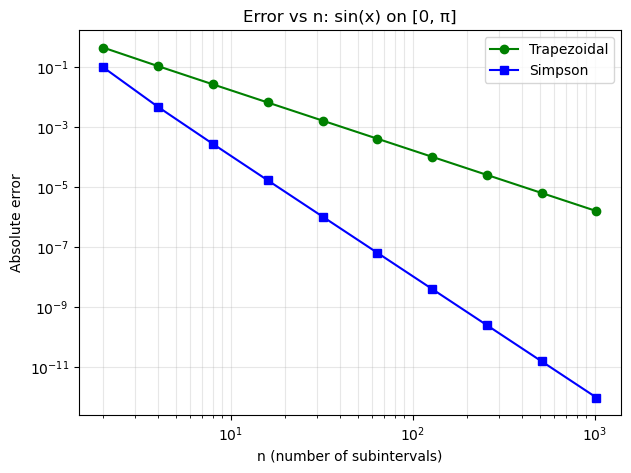

In [10]:
ns, et, es = compare(np.sin, 0, np.pi, 2.0, 'sin(x) on [0, π]')

## 5. Test 2: ∫₀^1 eˣ dx = e − 1

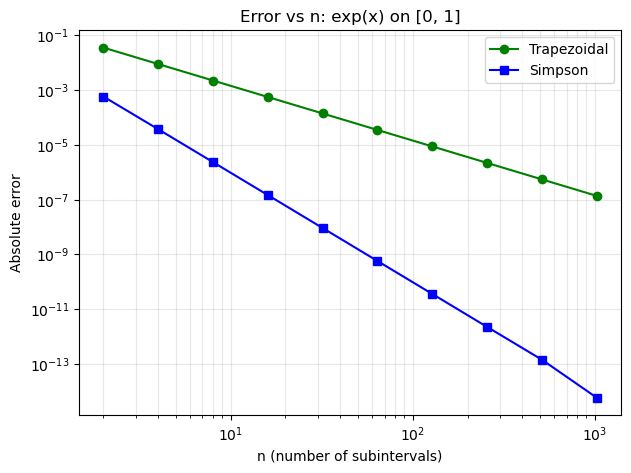

In [11]:
ns2, et2, es2 = compare(np.exp, 0, 1, np.e - 1, 'exp(x) on [0, 1]')

## 6. Observation 

In this exercise, we observe that Simpson’s rule gives a smaller error than the trapezoidal rule for every value of n tested. The gap widens as n increases: the trapezoidal error decreases like O(h²), while Simpson’s error decreases like O(h⁴).

In [12]:
## End 